# Ringkasan EDA

Temuan dari `01_eda.ipynb` yang jadi dasar keputusan di notebook ini:

1. **`building_id`** hanya identifier, tidak punya makna statistik -> tidak dipakai sebagai fitur (tetap ada di dataframe asli untuk keperluan submission).
2. **`age_building`** punya nilai placeholder 999 (sekitar 0,41% data) yang berarti "usia tidak diketahui" -> diubah menjadi `NaN`, lalu diimputasi median oleh pipeline (median dihitung dari data latih saja).
3. **`damage_grade`** (target) terdiri dari 5 kelas dengan distribusi tidak seimbang -> split memakai `stratify`, dan evaluasi memakai **macro F1** selain accuracy.
4. **Fitur lokasi** (`district_id`, `vdcmun_id`, `ward_id`) berkardinalitas tinggi. One-hot encoding akan membuat dimensi fitur meledak, jadi dipakai **`TargetEncoder`** dimana tiap lokasi diganti dengan rata-rata tingkat kerusakan di lokasi itu, dihitung hanya dari data train (dengan cross-fitting agar tidak bocor).
5. **Fitur struktur bangunan** (`foundation_type`, `roof_type`, dan seterusnya) di-encode dengan `OrdinalEncoder`. Untuk model berbasis pohon seperti Random Forest, ini cukup efektif dan jauh lebih hemat memori dibanding one-hot.
6. **Outlier** pada `plinth_area_sq_ft`, `height_ft_pre_eq`, dan `age_building` dibiarkan karena nilainya wajar secara fisik, dan Random Forest tidak sensitif terhadap skala maupun outlier.


# Import Library

In [93]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


`%autoreload 2` membuat perubahan pada file di `scripts/` otomatis terbaca tanpa harus restart kernel.

In [94]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

cwd = Path.cwd().resolve()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / 'scripts').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print('Root repo:', ROOT)


Root repo: C:\Users\Kiranna\OneDrive\Documents\VS Code\Structural Damage Classification


In [95]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import classification_report, confusion_matrix

from scripts.preprocess import TARGET_COL, load_data, split_train_validation
from scripts.feature_engineering import build_features
from scripts.train import (
    build_pipeline,
    tune_pipeline,
    evaluate,
    get_feature_importance,
    save_feature_importance_figure,
    save_model,
)
from scripts.predict import load_model

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

# Import Dataset

In [96]:
df = load_data('train.csv')

# Data Cleaning

### Handling age_building = 999

In [97]:
print('Jumlah age_building == 999 sebelum diubah:', (df['age_building'] == 999).sum())

df['age_building'] = df['age_building'].replace(999, np.nan)

print('Jumlah age_building == 999 setelah diubah:', (df['age_building'] == 999).sum())
print('Jumlah NaN di age_building sekarang       :', df['age_building'].isna().sum())


Jumlah age_building == 999 sebelum diubah: 2198
Jumlah age_building == 999 setelah diubah: 0
Jumlah NaN di age_building sekarang       : 2198


# Menentukan kolom fitur (X) dan target (Y)

In [98]:
X = build_features(df)
y = df[TARGET_COL]

print('X shape:', X.shape, '| y shape:', y.shape)

X shape: (533465, 15) | y shape: (533465,)


# Splitting

In [99]:
X_train, X_val, y_train, y_val = split_train_validation(X, y)
X_train.shape, X_val.shape

((426772, 15), (106693, 15))

In [100]:
pd.concat(
    [
        y_train.value_counts(normalize=True).sort_index().rename('train'),
        y_val.value_counts(normalize=True).sort_index().rename('validation'),
    ],
    axis=1,
).round(4)

,train,validation
damage_grade,,
Grade 1,0.1034,0.1034
Grade 2,0.1145,0.1145
Grade 3,0.1790,0.1790
Grade 4,0.2412,0.2412
Grade 5,0.3619,0.3619


# Preprocessing

In [101]:
baseline_pipeline = build_pipeline()
baseline_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('algo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categoric', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3

# Training (Baseline)

In [102]:
baseline_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('algo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](5,)","['Grade 1','Grade 2','Grade 3','Grade 4','Grade 5']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['count_floors_pre_eq','age_building','plinth_area_sq_ft',..., 'district_id','vdcmun_id','ward_id']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categoric', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are

# Evaluation (Baseline)

In [103]:
pd.DataFrame({
    'train': evaluate(baseline_pipeline, X_train, y_train),
    'validation': evaluate(baseline_pipeline, X_val, y_val),
}).round(4)

,train,validation
accuracy,0.6341,0.5830
macro_f1,0.6007,0.5382


In [104]:
y_pred_baseline = baseline_pipeline.predict(X_val)
print('Classification Report - Baseline (Validation):\n')
print(classification_report(y_val, y_pred_baseline))


Classification Report - Baseline (Validation):

              precision    recall  f1-score   support

     Grade 1       0.61      0.73      0.66     11034
     Grade 2       0.44      0.30      0.36     12216
     Grade 3       0.44      0.41      0.42     19098
     Grade 4       0.51      0.50      0.51     25738
     Grade 5       0.71      0.77      0.74     38607

    accuracy                           0.58    106693
   macro avg       0.54      0.54      0.54    106693
weighted avg       0.57      0.58      0.57    106693



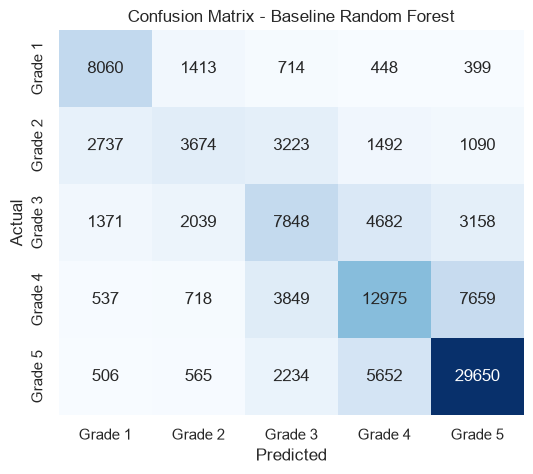

In [105]:
grade_order = ['Grade 1', 'Grade 2', 'Grade 3', 'Grade 4', 'Grade 5']
cm = confusion_matrix(y_val, y_pred_baseline, labels=grade_order)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=grade_order, yticklabels=grade_order)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Baseline Random Forest')
plt.show()


# Hyperparameter Tuning

In [106]:
search = tune_pipeline(build_pipeline(), X_train, y_train)
print('Best Params     :', search.best_params_)
print('Best CV Macro F1:', round(search.best_score_, 4))

cv_results = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
cv_results[['params', 'mean_test_score', 'rank_test_score']]

Fitting 2 folds for each of 4 candidates, totalling 8 fits
Best Params     : {'algo__n_estimators': 150, 'algo__min_samples_leaf': 3, 'algo__max_depth': 20, 'algo__class_weight': 'balanced_subsample'}
Best CV Macro F1: 0.5389


,params,mean_test_score,rank_test_score
3,"{'algo__n_estimators': 150, 'algo__min_samples...",0.538878,1
1,"{'algo__n_estimators': 100, 'algo__min_samples...",0.531884,2
0,"{'algo__n_estimators': 150, 'algo__min_samples...",0.508783,3
2,"{'algo__n_estimators': 100, 'algo__min_samples...",0.497620,4


# Evaluation (Final Model)

In [107]:
final_model = search.best_estimator_

comparison = pd.DataFrame({
    'baseline - train': evaluate(baseline_pipeline, X_train, y_train),
    'baseline - validation': evaluate(baseline_pipeline, X_val, y_val),
    'tuned - train': evaluate(final_model, X_train, y_train),
    'tuned - validation': evaluate(final_model, X_val, y_val),
}).round(4)
comparison

,baseline - train,baseline - validation,tuned - train,tuned - validation
accuracy,0.6341,0.5830,0.6325,0.5745
macro_f1,0.6007,0.5382,0.6148,0.5461


In [108]:
y_pred_final = final_model.predict(X_val)
print('Classification Report - Final Model (Validation):\n')
print(classification_report(y_val, y_pred_final))


Classification Report - Final Model (Validation):

              precision    recall  f1-score   support

     Grade 1       0.58      0.77      0.66     11034
     Grade 2       0.38      0.43      0.40     12216
     Grade 3       0.43      0.43      0.43     19098
     Grade 4       0.52      0.51      0.52     25738
     Grade 5       0.77      0.68      0.72     38607

    accuracy                           0.57    106693
   macro avg       0.54      0.56      0.55    106693
weighted avg       0.59      0.57      0.58    106693



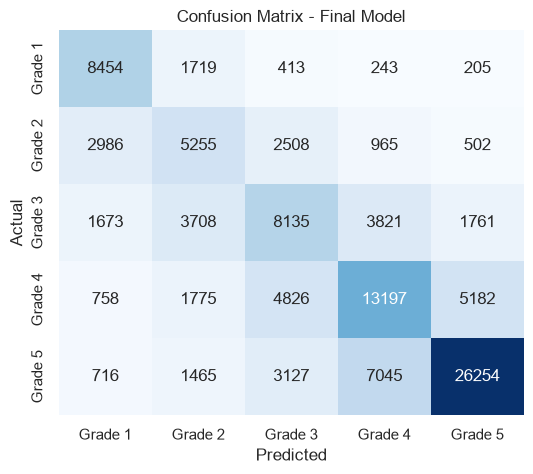

In [109]:
cm_final = confusion_matrix(y_val, y_pred_final, labels=grade_order)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=grade_order, yticklabels=grade_order)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Final Model')
plt.show()


# Feature Importance

Gambar tersimpan di: C:\Users\Kiranna\OneDrive\Documents\VS Code\Structural Damage Classification\reports\figures\feature_importance.png


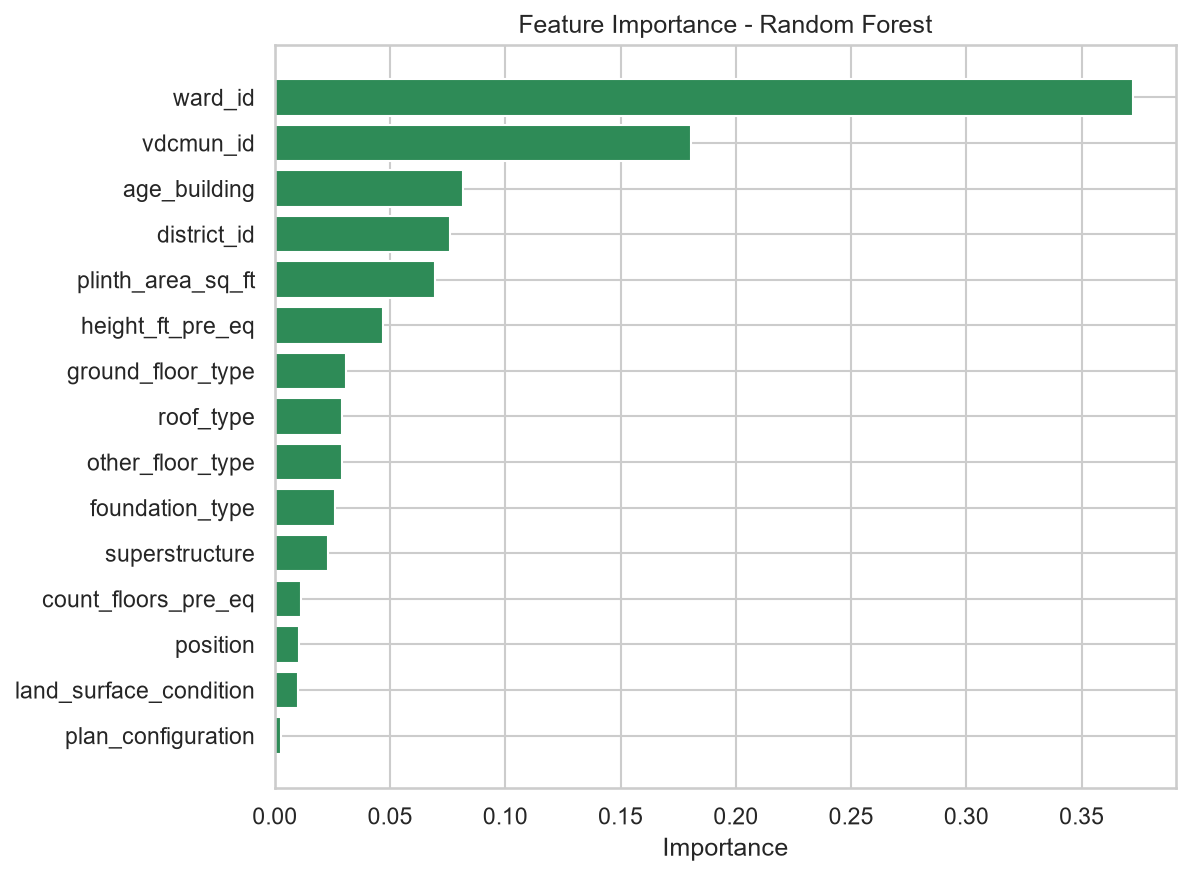

ward_id                   0.3723
vdcmun_id                 0.1805
age_building              0.0816
district_id               0.0761
plinth_area_sq_ft         0.0695
height_ft_pre_eq          0.0469
ground_floor_type         0.0309
roof_type                 0.0291
other_floor_type          0.0290
foundation_type           0.0262
superstructure            0.0232
count_floors_pre_eq       0.0113
position                  0.0105
land_surface_condition    0.0101
plan_configuration        0.0025
dtype: float64

In [110]:
importance = get_feature_importance(final_model)

figure_path = save_feature_importance_figure(importance)
print('Gambar tersimpan di:', figure_path)
display(Image(filename=str(figure_path)))

importance.round(4)

# Save Model

In [111]:
model_path = save_model(final_model)
print(f'Model tersimpan di: {model_path} ({model_path.stat().st_size / 1e6:.1f} MB)')

Model tersimpan di: C:\Users\Kiranna\OneDrive\Documents\VS Code\Structural Damage Classification\models\pipeline_model_rf.pkl (354.5 MB)
